<div style="background: linear-gradient(135deg, #1e50a0 0%, #2e6cc0 100%); padding: 36px 40px; border-radius: 10px; color: white; margin-bottom: 20px;">
    <h1 style="color: white; margin: 0 0 8px 0; font-size: 2em;">Introduction to PINNs | Heat Transfer Case</h1>
    <h2 style="color: #c8dcff; margin: 0 0 12px 0; font-weight: normal; font-size: 1.3em;">1D Steady-State Conduction with a Heat Source</h2>
    <p style="color: #a0bce0; margin: 0; font-size: 1em;">Pure PINN &nbsp;·&nbsp; Dirichlet &amp; Neumann BCs &nbsp;·&nbsp; Learning-rate schedulers &nbsp;·&nbsp; PyTorch</p>
    <hr>
    <p style="color: #a0bce0; margin: 0; font-size: 1em;">Author: A.S.Grm (aleksander.grm@fpp.uni-lj.si), 2026</p>
</div>

### Problem summary

A rod of length $L$ with constant thermal conductivity $k$ and uniform volumetric heat generation $q$:

$$k\,\frac{d^2T}{dx^2} + q = 0, \qquad x\in[0,L]$$

| Boundary | Type | Condition |
|---|---|---|
| $x=0$ | Dirichlet (fixed temperature) | $T(0)=T_0$ |
| $x=L$ | Neumann (insulated, zero heat flux) | $\dfrac{dT}{dx}(L)=0$ |

Analytical solution (used for validation): $\;T(x) = T_0 + \dfrac{q}{k}\Big(Lx - \dfrac{x^2}{2}\Big)$.
Default values: $L=1$ m, $k=1$ W/(m·K), $q=100$ W/m³, $T_0=300$ K $\Rightarrow T(x) = 300 + 100x - 50x^2$, with maximum $T(L)=350$ K.

**PINN:** network $x \mapsto \hat T(x)$, trained without any temperature data (pure physics):

$$\mathcal L = \frac{1}{N_f}\sum_i \Big(\frac{d^2\hat T}{dx^2}(x_i) + \frac{q}{k}\Big)^2 + \big(\hat T(0) - T_0\big)^2 + \Big(\frac{d\hat T}{dx}(L)\Big)^2$$

**Output strategies** (`bc_type`):
`0` raw output $\hat T = N(x)$ · `1` shifted output $\hat T = N(x) + T_0$ · `2` hard Dirichlet BC $\hat T = T_0 + x\,N(x)$ (exact at $x=0$, the BC loss term is dropped).

The same problem is trained with five learning-rate schedulers (`none`, `exponential`, `step`, `cosine`, `plateau`) from identical initial weights, so the schedules can be compared fairly.

| Code cell | Content |
|---|---|
| 1–3 | imports, compute device, physical parameters |
| 4 | neural network with three output strategies |
| 5–6 | PDE residual (autograd), domain points |
| 7 | training loop with learning-rate scheduler |
| 8–9 | experiment driver with validation, results dashboard |
| 10–11 | `main()` and entry point |

In [1]:
import time
import platform
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [2]:
# Prefer GPU (CUDA / AMD ROCm / Apple Silicon); fall back to CPU when no GPU is detected.
# dd = None  -> automatic selection
# dd = 'cpu' | 'cuda' | 'mps' -> force a specific device
def get_device(dd=None):

    if dd is None:
        if torch.cuda.is_available():
            device = torch.device("cuda")
            device_name = torch.cuda.get_device_name(0)
        elif torch.backends.mps.is_available():
            device = torch.device("mps")
            device_name = f"Apple Silicon ({platform.processor()})"
        else:
            device = torch.device("cpu")
            device_name = "GPU not detected – training will be slower"
    else:
        if dd == "cuda":
            device = torch.device("cuda")
            device_name = torch.cuda.get_device_name(0)
        elif dd == "mps":
            device = torch.device("mps")
            device_name = f"Apple Silicon ({platform.processor()})"
        elif dd == "cpu":
            device = torch.device("cpu")
            device_name = "CPU (forced)"
        else:
            raise ValueError(f"Device name is not supported: {dd}")

    print(f"Compute device : {device} ({device_name})")

    return device

In [3]:
# All physical constants of the problem in ONE container.
# Every function receives 'p' explicitly – no hidden hard-coded numbers
# (previously q = 100, k = 1 and T0 = 300 were repeated inside several functions).
@dataclass
class HeatParams:

    L:  float = 1.0      # rod length [m]
    k:  float = 1.0      # thermal conductivity [W/(m·K)]
    q:  float = 100.0    # volumetric heat generation [W/m^3]
    T0: float = 300.0    # Dirichlet temperature at x = 0 [K]

    # Analytical solution T(x) = T0 + (q/k) * (L*x - x^2/2), used ONLY for validation.
    # Works for NumPy arrays and scalars.
    def T_exact(self, x):
        return self.T0 + (self.q / self.k) * (self.L * x - 0.5 * x**2)

In [4]:
# Define a custom neural network class that inherits from PyTorch's base model class (nn.Module).
# Inheriting from nn.Module gives us built-in tracking of parameters, weights, and gradients.
class PINN1D(nn.Module):

    # The __init__ constructor runs when the model is instantiated, e.g. model = PINN1D(48, 3, 300.0).
    # It sets up the architecture (layers, dimensions) and the output strategy.
    def __init__(self, hidden_dim, num_layers, T0):

        # Call the constructor of the parent class (nn.Module).
        # This is strictly required by PyTorch to initialise internal parameter tracking.
        super().__init__()

        # Python list holding the layers in sequential order.
        # FIRST LAYER:
        # 1) nn.Linear(1, hidden_dim): fully-connected layer mapping 1 input coordinate x to hidden_dim neurons.
        # 2) nn.Tanh(): smooth, infinitely differentiable activation. The PDE needs d2T/dx2,
        #    so ReLU (second derivative = 0 almost everywhere) would be unsuitable.
        layers = [nn.Linear(1, hidden_dim), nn.Tanh()]

        # HIDDEN LAYERS: (num_layers - 1) additional blocks hidden_dim -> hidden_dim, each followed by tanh.
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.Tanh())

        # OUTPUT LAYER: hidden_dim -> 1 scalar output (temperature), linear (no activation).
        layers.append(nn.Linear(hidden_dim, 1))

        # nn.Sequential(*layers) unpacks the list and chains all operations sequentially.
        self.net = nn.Sequential(*layers)

        # Reference temperature used by output strategies 1 and 2 (= Dirichlet value T0).
        self.T0 = T0

        # Output strategy / boundary-condition mode (see forward). Default: 0.
        self.bc_type = 0

    # forward() defines how input x of shape (N, 1) is mapped to the temperature T of shape (N, 1).
    # PyTorch calls it automatically when we write model(x).
    def forward(self, x):

        if self.bc_type == 0:
            # Mode 0: raw network output. A freshly initialised network outputs values near 0,
            # i.e. ~300 K away from the target: very large initial losses, slow training.
            return self.net(x)

        elif self.bc_type == 1:
            # Mode 1: shift the output by T0. Initial predictions are already of the correct
            # magnitude (T ≈ 300 K); the network only has to learn the DEVIATION from T0.
            return self.net(x) + self.T0

        elif self.bc_type == 2:
            # Mode 2: HARD Dirichlet BC. At x = 0 the product x * net(x) vanishes, so
            # T(0) = T0 exactly for ANY weights; the left-BC loss term is no longer needed.
            # (Valid because the domain starts at x = 0.)
            return self.T0 + x * self.net(x)

        else:
            raise ValueError(f"Unknown bc_type {self.bc_type}; choose 0, 1 or 2.")

    # Setter: change the output strategy (0, 1 or 2) of an existing model.
    def set_BC_Type(self, bc_type):
        self.bc_type = bc_type

    # Getter: query the active output strategy.
    def get_BC_Type(self):
        return self.bc_type

In [5]:
def compute_pde_residual(model, x, p):
    """
    Computes the residual of the 1D steady heat conduction equation
        k d2T/dx2 + q = 0   ==>   R(x) = d2T/dx2 + q/k

    Parameters
    ----------
    model : nn.Module
        Neural network predicting the temperature T(x).
    x : torch.Tensor, shape (N, 1), requires_grad=True
        Spatial collocation points [m].
    p : HeatParams
        Physical parameters (q and k are used here).

    Returns
    -------
    pde_residual : torch.Tensor, shape (N, 1)
        PDE residual at the points x (target: 0).
    dT_dx : torch.Tensor, shape (N, 1)
        First derivative of the temperature with respect to x.
    """

    # Line 1: Forward pass – predicted temperature T(x).
    # Shape of x: [N, 1]  --->  shape of T: [N, 1]
    T = model(x)

    # Line 2: First derivative dT/dx with PyTorch's automatic differentiation (autograd).
    # The derivative is exact for the current network (no finite-difference step).
    dT_dx = torch.autograd.grad(
        outputs=T,                          # what we differentiate (temperature T)
        inputs=x,                           # with respect to what (position x)
        grad_outputs=torch.ones_like(T),    # weights of 1: T_i depends only on x_i, so this
                                            # returns the pointwise derivative dT_i/dx_i
        create_graph=True,                  # CRITICAL: keep dT_dx differentiable, so that
                                            # (a) the 2nd derivative can be taken and
                                            # (b) the loss can be back-propagated to the weights
    )[0]                                    # autograd returns a tuple; [0] extracts the tensor

    # Line 3: Second derivative d2T/dx2 – differentiate dT_dx with respect to x again.
    d2T_dx2 = torch.autograd.grad(
        outputs=dT_dx,
        inputs=x,
        grad_outputs=torch.ones_like(dT_dx),
        create_graph=True,                  # still needed: the loss built from d2T_dx2 is
                                            # back-propagated to the network weights
    )[0]

    # Line 4: Governing-equation residual. Dividing the PDE by k gives R = T'' + q/k.
    # If the network predicts the physically correct temperature everywhere, R(x) = 0.
    pde_residual = d2T_dx2 + p.q / p.k

    # Line 5: Return the residual and the first derivative (useful for the heat flux -k dT/dx).
    return pde_residual, dT_dx

In [6]:
def generate_domain_points(x_min, x_max, N_f, device):
    """
    Constructs the points on which the loss terms are evaluated.

    Parameters
    ----------
    x_min, x_max : float
        Domain boundaries [m].
    N_f : int
        Number of interior collocation points for the PDE residual.
    device : torch.device or str
        Target computing device.

    Returns
    -------
    x_f : torch.Tensor, shape (N_f, 1), requires_grad=True
        Collocation points for the physics loss (no temperature labels needed –
        the PDE itself is the "label").
    x_bc_left : torch.Tensor, shape (1, 1)
        Left boundary point (Dirichlet BC).
    x_bc_right : torch.Tensor, shape (1, 1), requires_grad=True
        Right boundary point (Neumann BC).
    """

    # =========================================================================
    # 1. INTERIOR COLLOCATION POINTS (physics loss / PDE residual)
    # =========================================================================
    # torch.linspace: N_f uniformly spaced values from x_min to x_max, shape [N_f].
    # .unsqueeze(1): reshape to a column [N_f, 1]; nn.Linear expects [batch_size, num_features].
    # .to(device): place the tensor on CPU or GPU.
    x_f = torch.linspace(x_min, x_max, N_f).unsqueeze(1).to(device)

    # requires_grad = True – CRITICAL FOR PINNs: autograd must track x_f in order to
    # compute the spatial derivatives dT/dx and d2T/dx2 at these points.
    x_f.requires_grad_(True)

    # =========================================================================
    # 2. BOUNDARY CONDITION POINTS
    # =========================================================================
    # Left Dirichlet point x = x_min. Only T(x_min) is evaluated -> no gradient needed.
    x_bc_left = torch.tensor([[x_min]], device=device)

    # Right Neumann point x = x_max. The BC prescribes dT/dx, so autograd must
    # differentiate the prediction with respect to this point -> requires_grad = True.
    x_bc_right = torch.tensor([[x_max]], device=device, requires_grad=True)

    return x_f, x_bc_left, x_bc_right

In [7]:
def make_scheduler(optimizer, scheduler_type, epochs):
    """
    Returns a learning-rate scheduler for the given optimizer (or None).

    scheduler_type
    --------------
    'none'        : constant learning rate.
    'exponential' : smooth decay every epoch, lr = lr0 * gamma^epoch.
                    gamma = 0.9995 over 8000 epochs: 1e-3 -> ~1.8e-5.
    'step'        : staircase decay, lr halved every epochs/4 epochs
                    (8000 epochs: 1e-3, 5e-4, 2.5e-4, 1.25e-4).
    'cosine'      : half-cosine from lr0 down to eta_min = 1e-6 over all epochs.
    'plateau'     : adaptive – lr halved only when the loss has not improved for
                    'patience' = 500 consecutive epochs.
    """
    if scheduler_type == 'none':
        return None
    elif scheduler_type == 'exponential':
        return torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9995)
    elif scheduler_type == 'step':
        return torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1, epochs // 4), gamma=0.5)
    elif scheduler_type == 'cosine':
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    elif scheduler_type == 'plateau':
        return torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=500)
    else:
        raise ValueError(
            f"Invalid scheduler_type '{scheduler_type}'. "
            "Choose from: 'none', 'exponential', 'step', 'cosine', 'plateau'."
        )


def train_pinn(model, p, x_f, x_bc_left, x_bc_right, epochs, lr, print_every, scheduler_type='none'):
    """
    Trains the 1D steady heat-conduction PINN with Adam and an optional lr scheduler.

    Parameters
    ----------
    model : PINN1D
    p : HeatParams
    x_f, x_bc_left, x_bc_right : torch.Tensor
        Collocation and boundary points (see generate_domain_points).
    epochs : int
        Number of optimisation steps.
    lr : float
        Initial Adam learning rate.
    print_every : int
        Logging interval in epochs.
    scheduler_type : str
        See make_scheduler. 'none' = constant learning rate.

    Returns
    -------
    history : dict of lists
        Per-epoch 'total', 'pde', 'bc_left', 'bc_right' losses and 'lr'.
    """

    # 1. Adam optimizer over all learnable weights and biases.
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # 2. Learning-rate scheduler (None = constant lr).
    scheduler = make_scheduler(optimizer, scheduler_type, epochs)

    history = {"total": [], "pde": [], "bc_left": [], "bc_right": [], "lr": []}

    # 3. Main optimisation loop.
    for epoch in range(epochs + 1):

        # CLEAR GRADIENTS: PyTorch accumulates gradients by default.
        optimizer.zero_grad()

        # =====================================================================
        # STEP 1: PDE physics loss (interior collocation points)
        # =====================================================================
        res, _ = compute_pde_residual(model, x_f, p)
        loss_pde = torch.mean(res**2)

        # =====================================================================
        # STEP 2: Left Dirichlet BC loss: T(0) = T0
        # =====================================================================
        # torch.mean turns the (1, 1) tensor into a scalar, as required for logging/schedulers.
        T_left = model(x_bc_left)
        loss_bc_left = torch.mean((T_left - p.T0)**2)

        # =====================================================================
        # STEP 3: Right Neumann BC loss: dT/dx(L) = 0 (insulated end)
        # =====================================================================
        T_right = model(x_bc_right)
        dT_dx_right = torch.autograd.grad(
            outputs=T_right,
            inputs=x_bc_right,
            grad_outputs=torch.ones_like(T_right),
            create_graph=True,                 # the BC loss is back-propagated to the weights
        )[0]
        loss_bc_right = torch.mean((dT_dx_right - 0.0)**2)

        # =====================================================================
        # STEP 4: Total composite loss
        # =====================================================================
        if model.get_BC_Type() != 2:
            total_loss = loss_pde + loss_bc_left + loss_bc_right
        else:
            # bc_type 2: T(0) = T0 holds exactly by construction -> omit the left-BC term.
            total_loss = loss_pde + loss_bc_right

        # =====================================================================
        # STEP 5: Backpropagation, parameter update, scheduler step
        # =====================================================================
        # BACKWARD PASS: d(total_loss)/d(weight) for every weight and bias (chain rule).
        total_loss.backward()

        # OPTIMIZER STEP: move the weights in the direction that decreases the loss.
        optimizer.step()

        # SCHEDULER STEP: ReduceLROnPlateau needs the monitored loss value; the others do not.
        if scheduler is not None:
            if scheduler_type == 'plateau':
                scheduler.step(total_loss.item())
            else:
                scheduler.step()

        # RECORD METRICS (.item(): one-element tensor -> Python float).
        current_lr = optimizer.param_groups[0]['lr']
        history["total"].append(total_loss.item())
        history["pde"].append(loss_pde.item())
        history["bc_left"].append(loss_bc_left.item())
        history["bc_right"].append(loss_bc_right.item())
        history["lr"].append(current_lr)

        if epoch % print_every == 0:
            print(f"Epoch {epoch:5d} | Loss: {total_loss.item():.4e} | "
                  f"PDE: {loss_pde.item():.4e} | BC L: {loss_bc_left.item():.4e} | "
                  f"BC R: {loss_bc_right.item():.4e} | lr: {current_lr:.2e}")

    return history

In [8]:
def compute_pinn_experiment(p, hidden_dim, num_layers, bc_type, N_f, epochs, lr, schedulers, seed, device):
    """
    Full PINN pipeline, repeated for each learning-rate scheduler:
      1. domain collocation and boundary points
      2. fresh network with IDENTICAL initial weights (same seed) for a fair comparison
      3. training
      4. validation against the analytical solution

    Parameters
    ----------
    p : HeatParams
    hidden_dim, num_layers : int
        Network width and number of hidden layers.
    bc_type : int
        Output strategy 0, 1 or 2 (see PINN1D.forward).
    N_f : int
        Number of collocation points.
    epochs : int
        Training epochs per scheduler.
    lr : float
        Initial learning rate.
    schedulers : list of str
        Schedulers to compare, e.g. ['none', 'exponential', 'step', 'cosine', 'plateau'].
    seed : int
        Seed for reproducible weight initialisation.
    device : torch.device

    Returns
    -------
    experiments : dict
        One entry per scheduler: model, history, test grid, prediction, exact solution, errors.
    """

    # =========================================================================
    # STEP 1: DOMAIN & BOUNDARY POINTS (shared by all runs)
    # =========================================================================
    x_f, x_bc_left, x_bc_right = generate_domain_points(0.0, p.L, N_f, device)

    # Independent test grid (finer than the collocation grid) for validation.
    x_test = torch.linspace(0.0, p.L, 200).unsqueeze(1).to(device)
    x_test_np = x_test.cpu().numpy()
    T_exact = p.T_exact(x_test_np)

    experiments = {}

    # =========================================================================
    # STEP 2: TRAIN ONE MODEL PER SCHEDULER
    # =========================================================================
    for scheduler_name in schedulers:
        print("\n=======================================================")
        print(f"   PINN TRAINING WITH '{scheduler_name.upper()}' SCHEDULER")
        print("=======================================================")

        # FIX SEED BEFORE EACH RUN: identical random weight initialisation for every
        # scheduler, so differences in the results come from the schedule only.
        torch.manual_seed(seed)
        np.random.seed(seed)

        model = PINN1D(hidden_dim=hidden_dim, num_layers=num_layers, T0=p.T0).to(device)
        model.set_BC_Type(bc_type)

        t0 = time.time()
        history = train_pinn(
            model, p, x_f, x_bc_left, x_bc_right,
            epochs=epochs, lr=lr, print_every=max(1, epochs // 4),
            scheduler_type=scheduler_name,
        )
        train_time = time.time() - t0

        # =====================================================================
        # STEP 3: VALIDATION AGAINST THE ANALYTICAL SOLUTION
        # =====================================================================
        # torch.no_grad(): no computational graph -> faster evaluation, less memory.
        with torch.no_grad():
            T_pred = model(x_test).cpu().numpy()

        abs_error = np.abs(T_pred - T_exact)
        max_error = abs_error.max()
        mae = abs_error.mean()
        # Relative L2 error: scale-independent accuracy measure
        rel_l2 = np.linalg.norm(T_pred - T_exact) / np.linalg.norm(T_exact)

        print(f"\n>>> '{scheduler_name.upper()}' scheduler – validation ({train_time:.1f} s):")
        print(f"    Maximum absolute error: {max_error:.4e} K")
        print(f"    Mean absolute error   : {mae:.4e} K")
        print(f"    Relative L2 error     : {rel_l2:.4e}")

        experiments[scheduler_name] = {
            'model': model,
            'history': history,
            'x_test': x_test_np,
            'T_pred': T_pred,
            'T_exact': T_exact,
            'abs_error': abs_error,
            'max_error': max_error,
            'mae': mae,
            'rel_l2': rel_l2,
        }

    return experiments

In [9]:
# One colour / line style per scheduler, shared by all panels.
STYLES = {
    'none':        {'color': 'black',  'linestyle': '-'},
    'exponential': {'color': 'blue',   'linestyle': '-'},
    'step':        {'color': 'orange', 'linestyle': '--'},
    'cosine':      {'color': 'purple', 'linestyle': '-.'},
    'plateau':     {'color': 'green',  'linestyle': ':'},
}


def plot_pinn_results(results, p):
    """
    2 x 2 dashboard:
      (a) temperature profile T(x): PINNs vs analytical solution
      (b) absolute error |T_PINN - T_exact| along the rod (log scale)
      (c) total training loss per scheduler (log scale)
      (d) learning-rate trajectories (log scale)
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    first = next(iter(results.values()))
    x = first['x_test']

    # =========================================================================
    # PANEL (a): TEMPERATURE PROFILE
    # =========================================================================
    ax = axes[0, 0]
    ax.plot(x, first['T_exact'], 'r-', linewidth=4, alpha=0.35, label='Analytical solution', zorder=2)
    for name, exp in results.items():
        ax.plot(x, exp['T_pred'], label=f"PINN ({name})", linewidth=1.5, alpha=0.9, zorder=3, **STYLES[name])
    ax.scatter([0], [p.T0], color='green', s=60, zorder=5, label=f'Dirichlet BC $T(0)={p.T0:.0f}$ K')
    ax.set_title("(a) Steady temperature profile $T(x)$", fontsize=12, fontweight='bold')
    ax.set_xlabel("Position $x$ [m]")
    ax.set_ylabel("Temperature $T$ [K]")
    ax.legend(fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

    # =========================================================================
    # PANEL (b): ABSOLUTE ERROR ALONG THE ROD
    # =========================================================================
    # The profiles in (a) usually overlap; the error plot reveals the differences.
    ax = axes[0, 1]
    for name, exp in results.items():
        ax.semilogy(x, exp['abs_error'], label=f"{name} (max {exp['max_error']:.1e} K)", linewidth=1.5, **STYLES[name])
    ax.set_title("(b) Absolute error vs analytical solution", fontsize=12, fontweight='bold')
    ax.set_xlabel("Position $x$ [m]")
    ax.set_ylabel("$|T_{PINN} - T_{exact}|$ [K]")
    ax.legend(fontsize=9)
    ax.grid(True, which='both', linestyle=':', alpha=0.6)

    # =========================================================================
    # PANEL (c): LOSS CONVERGENCE
    # =========================================================================
    ax = axes[1, 0]
    for name, exp in results.items():
        ax.semilogy(exp['history']['total'], label=name, linewidth=1.2, alpha=0.85, **STYLES[name])
    ax.set_title("(c) Training loss convergence", fontsize=12, fontweight='bold')
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Total loss (log scale)")
    ax.legend(fontsize=9)
    ax.grid(True, which='both', linestyle=':', alpha=0.6)

    # =========================================================================
    # PANEL (d): LEARNING-RATE TRAJECTORIES
    # =========================================================================
    ax = axes[1, 1]
    for name, exp in results.items():
        ax.semilogy(exp['history']['lr'], label=name, linewidth=1.8, **STYLES[name])
    ax.set_title("(d) Learning-rate schedules", fontsize=12, fontweight='bold')
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Learning rate (log scale)")
    ax.legend(fontsize=9)
    ax.grid(True, which='both', linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

In [10]:
def main(dd):
    """
    Main execution pipeline for 1D steady heat conduction with a PINN:
    1. Selects the compute device.
    2. Defines physical parameters and hyperparameters.
    3. Trains the PINN with several learning-rate schedulers and validates each run.
    4. Displays the results dashboard.
    """
    print("=======================================================")
    print("   1D STEADY HEAT CONDUCTION PINN WORKFLOW")
    print("=======================================================\n")

    # -------------------------------------------------------------------------
    # STEP 1: DEVICE CONFIGURATION
    # -------------------------------------------------------------------------
    device = get_device(dd)

    # -------------------------------------------------------------------------
    # STEP 2: PHYSICAL PARAMETERS & HYPERPARAMETERS
    # -------------------------------------------------------------------------
    p = HeatParams(L=1.0, k=1.0, q=100.0, T0=300.0)

    hidden_dim    = 48       # neurons per hidden layer
    num_layers    = 3        # hidden layers
    bc_type       = 1        # output strategy: 1 = shifted output (+T0) for well-scaled gradients
    N_f           = 100      # interior collocation points
    epochs        = 8000     # training epochs per scheduler
    learning_rate = 1e-3     # initial Adam learning rate
    schedulers    = ['none', 'exponential', 'step', 'cosine', 'plateau']
    seed          = 42       # identical initial weights for every scheduler

    # -------------------------------------------------------------------------
    # STEP 3: RUN PINN EXPERIMENTS ACROSS SCHEDULERS
    # -------------------------------------------------------------------------
    results = compute_pinn_experiment(
        p, hidden_dim, num_layers, bc_type, N_f,
        epochs, learning_rate, schedulers, seed, device,
    )

    # Compact summary table of the validation errors
    print("\nSummary                max|err| [K]   MAE [K]     rel. L2")
    for name, exp in results.items():
        print(f"  {name:<12s}        {exp['max_error']:.3e}    {exp['mae']:.3e}   {exp['rel_l2']:.3e}")

    # -------------------------------------------------------------------------
    # STEP 4: VISUALISE
    # -------------------------------------------------------------------------
    plot_pinn_results(results, p)

    print("=======================================================")
    print("   PINN WORKFLOW SUCCESSFULLY COMPLETED!")
    print("=======================================================")

    return results

   1D STEADY HEAT CONDUCTION PINN WORKFLOW

Compute device : cuda (AMD Radeon RX 7600)

   PINN TRAINING WITH 'NONE' SCHEDULER
Epoch     0 | Loss: 1.0015e+04 | PDE: 1.0015e+04 | BC L: 1.0621e-02 | BC R: 5.5980e-03 | lr: 1.00e-03
Epoch  2000 | Loss: 7.0413e+01 | PDE: 1.0997e+01 | BC L: 3.1742e+01 | BC R: 2.7674e+01 | lr: 1.00e-03
Epoch  4000 | Loss: 3.6624e-01 | PDE: 1.8253e-01 | BC L: 9.6269e-02 | BC R: 8.7439e-02 | lr: 1.00e-03
Epoch  6000 | Loss: 4.2081e-03 | PDE: 4.1716e-03 | BC L: 1.7226e-05 | BC R: 1.9287e-05 | lr: 1.00e-03
Epoch  8000 | Loss: 4.3615e+00 | PDE: 4.3518e+00 | BC L: 2.4319e-04 | BC R: 9.4822e-03 | lr: 1.00e-03

>>> 'NONE' scheduler – validation (18.5 s):
    Maximum absolute error: 7.3059e-02 K
    Mean absolute error   : 1.8653e-02 K
    Relative L2 error     : 7.3177e-05

   PINN TRAINING WITH 'EXPONENTIAL' SCHEDULER
Epoch     0 | Loss: 1.0015e+04 | PDE: 1.0015e+04 | BC L: 1.0621e-02 | BC R: 5.5980e-03 | lr: 1.00e-03
Epoch  2000 | Loss: 1.7667e+02 | PDE: 2.7296e+01

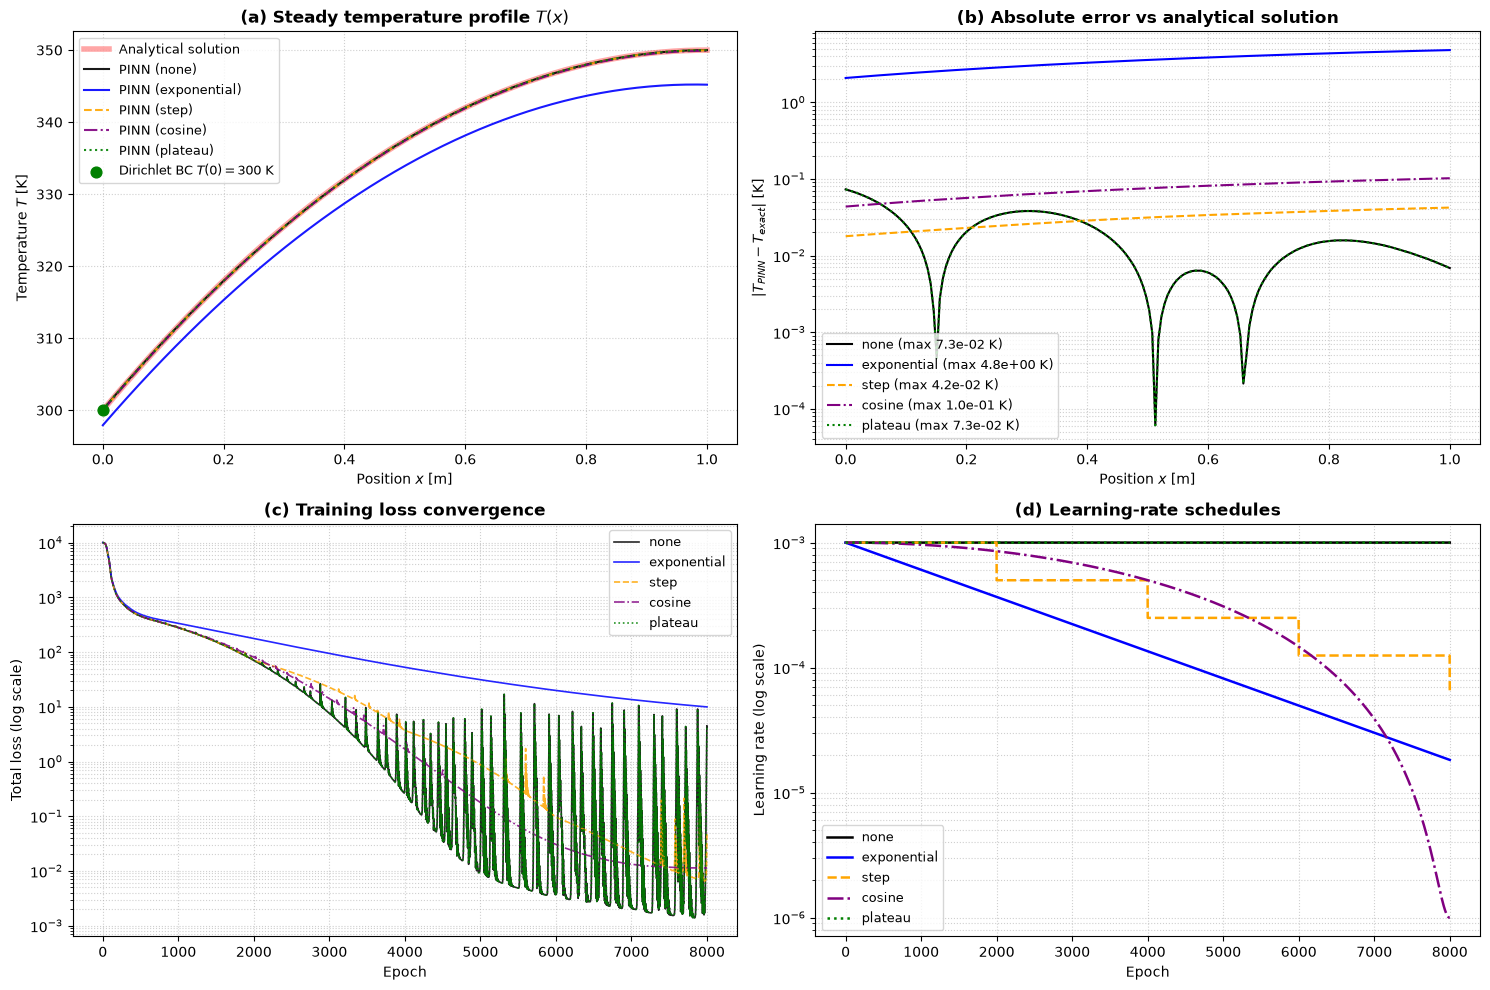

   PINN WORKFLOW SUCCESSFULLY COMPLETED!


In [11]:
# Standard Python entry point check: allows the code to be run as a script
# or imported as a module into another notebook.
if __name__ == "__main__":

    # Which device: CPU, Apple-Silicon GPU (MPS), CUDA GPU, or automatic (None).
    dd = ['cpu', 'mps', 'cuda', None]
    results = main(dd[3])